# 08 — Le modèle complet : `GPTLanguageModel`

**Chapitre 2** · durée conseillée : 25 min · CPU uniquement

![Parcours](figures/00_parcours.svg)

Toutes les pièces sont prêtes. Il reste à les **assembler** et à ajouter la dernière : l'**embedding de position**. Ce notebook montre le code complet du mini-GPT, le fait tourner **sans l'entraîner**, et vérifie ses propriétés essentielles.

**À la fin de ce notebook, vous saurez :**
1. lire `GPTLanguageModel` de haut en bas et donner la forme de chaque tenseur ;
2. expliquer pourquoi on **ajoute** un embedding de position ;
3. vérifier que le modèle complet est **causal** ;
4. expliquer `generate` (fenêtre de `block_size`, dernière position, tirage).

In [1]:
# Préparation : imports et module partagé du chapitre
import math
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

import minigpt  # fichier minigpt.py, à côté de ce notebook
torch.manual_seed(1337)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| périphérique :", device)

texte, tok, train_data, val_data = minigpt.preparer_donnees("shakespeare")
V = tok.vocab_size

PyTorch 2.14.1+cu130 | périphérique : cpu


## 1. Pourquoi un embedding de position ?

Au notebook 05 : l'attention travaille sur un **ensemble** de vecteurs. Rien dans $QK^\top$ ne dit qui est avant qui (le masque dit seulement *qui a le droit de lire qui*). Or l'ordre compte énormément : `"chien"` ≠ `"niche"`.

**Solution (GPT-2) :** une deuxième table apprise, `nn.Embedding(block_size, C)`, qui associe un vecteur à chaque **position** `0, 1, …, T−1`. On l'**additionne** à l'embedding du caractère :

$$x_t = \underbrace{E_{\text{token}}[\text{idx}_t]}_{\text{quel caractère ?}} + \underbrace{E_{\text{pos}}[t]}_{\text{où ?}}$$

Un même `e` aura ainsi une représentation différente en position 0 et en position 5. Les tokens ont la forme `(B, T, C)`, les positions `(T, C)` : PyTorch ajoute **la même table de positions à chacun des `B` exemples** (*broadcasting*).

> Le Transformer original utilisait des sinusoïdes **fixes** au lieu d'une table apprise ; les modèles récents utilisent souvent RoPE (rotations). L'idée reste la même : injecter l'ordre.

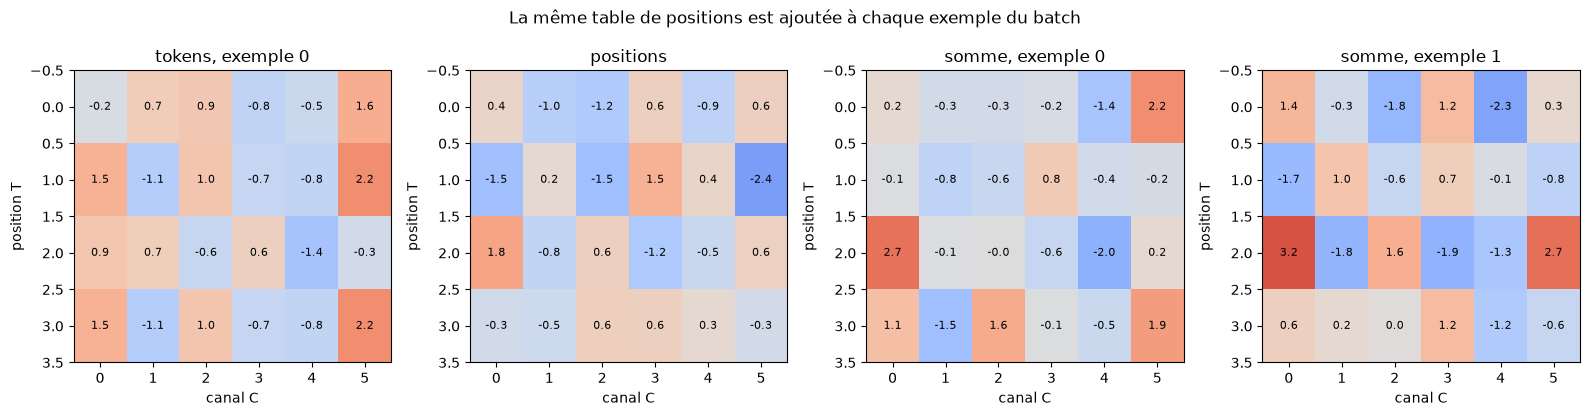

Le token 1 est en position 1 et 3 dans l'exemple 0 :
  même embedding de token ? True
  même vecteur final ?      False


In [2]:
B_vis, T_vis, C_vis = 2, 4, 6
indices = torch.tensor([[0, 1, 2, 1], [2, 0, 1, 2]])
gen = torch.Generator().manual_seed(2026)
table_tokens = torch.randn(3, C_vis, generator=gen)
table_positions = torch.randn(T_vis, C_vis, generator=gen)
tok_emb = table_tokens[indices]          # (2, 4, 6)
x_demo = tok_emb + table_positions       # (2, 4, 6) + (4, 6) -> (2, 4, 6)

fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
for ax, M, titre in [(axes[0], tok_emb[0], "tokens, exemple 0"), (axes[1], table_positions, "positions"),
                     (axes[2], x_demo[0], "somme, exemple 0"), (axes[3], x_demo[1], "somme, exemple 1")]:
    ax.imshow(M, cmap="coolwarm", vmin=-4, vmax=4, aspect="auto")
    for i in range(T_vis):
        for j in range(C_vis):
            ax.text(j, i, f"{M[i, j]:.1f}", ha="center", va="center", fontsize=8)
    ax.set_title(titre); ax.set_xlabel("canal C"); ax.set_ylabel("position T")
fig.suptitle("La même table de positions est ajoutée à chaque exemple du batch"); fig.tight_layout(); plt.show()
print("Le token 1 est en position 1 et 3 dans l'exemple 0 :")
print("  même embedding de token ?", torch.equal(tok_emb[0, 1], tok_emb[0, 3]))
print("  même vecteur final ?     ", torch.equal(x_demo[0, 1], x_demo[0, 3]))

## 2. Le code complet

![Le mini-GPT](figures/04_decoder_only.svg)

Voici **tout** le modèle, dans l'ordre où nous l'avons construit. C'est exactement le code de `minigpt.py`.

| Classe | Rôle | Notebook |
|---|---|---|
| `Head` | une tête d'attention causale | 05 |
| `MultiHeadAttention` | `n_head` têtes + projection | 05 |
| `FeedForward` | `C → 4C → ReLU → C` + dropout | 06 |
| `Block` | LN → attention → `+`, LN → FeedForward → `+` | 07 |
| `GPTLanguageModel` | embeddings → blocs → LN → `lm_head` ; loss ; `generate` | ici |

In [3]:
class Head(nn.Module):
    """Une tête d'auto-attention causale."""

    def __init__(self, n_embd, head_size, block_size, dropout):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)    # « ce que je contiens »
        self.query = nn.Linear(n_embd, head_size, bias=False)  # « ce que je cherche »
        self.value = nn.Linear(n_embd, head_size, bias=False)  # « ce que je transmets »
        # Le masque n'est PAS un paramètre : register_buffer le range avec le modèle
        # (et le déplace sur le GPU avec lui) sans que l'optimiseur y touche.
        self.register_buffer("tril", torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)                                          # (B, T, hs)
        q = self.query(x)                                        # (B, T, hs)
        wei = q @ k.transpose(-2, -1) * k.shape[-1] ** -0.5      # (B, T, T) scores
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float("-inf"))  # interdire le futur
        wei = F.softmax(wei, dim=-1)                             # chaque ligne somme à 1
        wei = self.dropout(wei)
        v = self.value(x)                                        # (B, T, hs)
        return wei @ v                                           # (B, T, hs)


class MultiHeadAttention(nn.Module):
    """Plusieurs têtes en parallèle, concaténées puis reprojetées sur n_embd canaux."""

    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        head_size = n_embd // n_head
        self.heads = nn.ModuleList(
            [Head(n_embd, head_size, block_size, dropout) for _ in range(n_head)]
        )
        self.proj = nn.Linear(n_head * head_size, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)    # (B, T, n_head*hs)
        return self.dropout(self.proj(out))                     # (B, T, n_embd)


class FeedForward(nn.Module):
    """Petit réseau appliqué indépendamment à chaque position : C -> 4C -> ReLU -> C."""

    def __init__(self, n_embd, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    """Bloc Transformer (pré-norm) : communication (attention) puis calcul (FeedForward)."""

    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(n_embd)
        self.sa = MultiHeadAttention(n_embd, n_head, block_size, dropout)
        self.ln2 = nn.LayerNorm(n_embd)
        self.ffwd = FeedForward(n_embd, dropout)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))     # connexion résiduelle n°1
        x = x + self.ffwd(self.ln2(x))   # connexion résiduelle n°2
        return x


class GPTLanguageModel(nn.Module):
    """Mini-GPT decoder-only, au niveau caractère."""

    def __init__(self, vocab_size, block_size=64, n_embd=64, n_head=4, n_layer=4, dropout=0.2):
        super().__init__()
        self.block_size = block_size
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(
            *[Block(n_embd, n_head, block_size, dropout) for _ in range(n_layer)]
        )
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding_table(idx)                                    # (B, T, C)
        pos_emb = self.position_embedding_table(torch.arange(T, device=idx.device))  # (T, C)
        x = tok_emb + pos_emb                    # (B, T, C)  broadcasting sur B
        x = self.blocks(x)                       # (B, T, C)
        x = self.ln_f(x)                         # (B, T, C)
        logits = self.lm_head(x)                 # (B, T, V)

        loss = None
        if targets is not None:
            B, T, V = logits.shape
            loss = F.cross_entropy(logits.view(B * T, V), targets.view(B * T))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size:]          # au plus block_size caractères
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature       # dernière position seulement
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

### Lire `forward` ligne par ligne

| Ligne | Forme | Commentaire |
|---|---|---|
| `idx` | `(B, T)` | indices des caractères |
| `tok_emb` | `(B, T, C)` | *quel* caractère |
| `pos_emb` | `(T, C)` | *où* : positions `0 … T−1` |
| `x = tok_emb + pos_emb` | `(B, T, C)` | entrée du flux résiduel |
| `self.blocks(x)` | `(B, T, C)` | `n_layer` × (communication + calcul) |
| `self.ln_f(x)` | `(B, T, C)` | dernière normalisation |
| `self.lm_head(x)` | `(B, T, V)` | un score par caractère possible, à chaque position |
| `F.cross_entropy(...)` | scalaire | reshape `(B·T, V)` du notebook 03 |

**Différence avec le bigramme :** la table `(V, V)` du bigramme sautait directement de l'indice aux logits. Ici, la table `(V, C)` ne donne qu'une **représentation** ; ce sont les blocs qui construisent la prédiction en regardant le contexte, et `lm_head` qui la traduit en `V` scores.

## 3. Instancier le modèle

In [4]:
config = dict(block_size=64, n_embd=64, n_head=4, n_layer=4, dropout=0.2)
torch.manual_seed(1337)
model = GPTLanguageModel(V, **config).to(device)
print(model)
print(f"\nparamètres entraînables : {sum(p.numel() for p in model.parameters()):,}")
print("buffers (non entraînables) :", [n for n, _ in model.named_buffers()][:2], "...")

GPTLanguageModel(
  (token_embedding_table): Embedding(65, 64)
  (position_embedding_table): Embedding(64, 64)
  (blocks): Sequential(
    (0): Block(
      (ln1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (sa): MultiHeadAttention(
        (heads): ModuleList(
          (0-3): 4 x Head(
            (key): Linear(in_features=64, out_features=16, bias=False)
            (query): Linear(in_features=64, out_features=16, bias=False)
            (value): Linear(in_features=64, out_features=16, bias=False)
            (dropout): Dropout(p=0.2, inplace=False)
          )
        )
        (proj): Linear(in_features=64, out_features=64, bias=True)
        (dropout): Dropout(p=0.2, inplace=False)
      )
      (ln2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (ffwd): FeedForward(
        (net): Sequential(
          (0): Linear(in_features=64, out_features=256, bias=True)
          (1): ReLU()
          (2): Linear(in_features=256, out_featu

## 4. Un passage *forward* sur un vrai batch

In [5]:
xb, yb = minigpt.get_batch(train_data, batch_size=8, block_size=config["block_size"], device=device)
logits, loss = model(xb, yb)
print("idx    :", tuple(xb.shape))
print("logits :", tuple(logits.shape), "= (B, T, V)")
print(f"loss   : {loss.item():.3f}   (référence uniforme log V = {math.log(V):.3f})")

idx    : (8, 64)
logits : (8, 64, 65) = (B, T, V)
loss   : 4.352   (référence uniforme log V = 4.174)


La loss initiale est **proche de `log V`** : le modèle non entraîné est presque uniforme (ce n'était pas le cas du bigramme, dont la table `N(0,1)` donnait directement des logits bruités ; ici les logits passent par une LayerNorm et une `nn.Linear` dont l'initialisation est petite).

## 5. Vérifier la causalité du modèle complet

Test simple et décisif : si l'on change le caractère à la position `t`, les logits des positions **avant** `t` ne doivent pas bouger. (On passe en `model.eval()` pour couper le dropout, sinon deux passages différeraient de toute façon.)

In [6]:
model.eval()
x1 = xb[:1].clone()
x2 = x1.clone(); x2[0, 40] = (x2[0, 40] + 1) % V          # on change UNIQUEMENT la position 40
l1, _ = model(x1); l2, _ = model(x2)
diff = (l1 - l2).abs().amax(-1)[0]
print("positions dont les logits ont changé :", [t for t in range(diff.shape[0]) if diff[t] > 1e-5])
assert diff[:40].max() < 1e-5, "fuite d'information du futur !"
print("Positions 0 à 39 intactes : le modèle complet est causal.")
model.train();

positions dont les logits ont changé : [40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63]
Positions 0 à 39 intactes : le modèle complet est causal.


## 6. Générer (sans entraînement)

`generate` répète :
1. **couper** le contexte aux `block_size` derniers caractères : l'embedding de position n'a que `block_size` lignes, et le masque `tril` aussi ;
2. calculer les logits et ne garder que la **dernière position** ;
3. softmax → `torch.multinomial` → ajouter le caractère tiré au contexte.

Que se passe-t-il si l'on oublie l'étape 1 ?

In [7]:
trop_long = torch.zeros((1, config["block_size"] + 1), dtype=torch.long, device=device)
try:
    model(trop_long)
except Exception as e:
    print("Sans recadrage :", type(e).__name__, "-", str(e)[:90])

model.eval()
torch.manual_seed(0)
debut = torch.full((1, 1), tok.stoi["\n"], dtype=torch.long, device=device)
print("\nTexte généré par le modèle NON entraîné :\n")
print(tok.decode(model.generate(debut, max_new_tokens=120)[0]))
model.train();

Sans recadrage : IndexError - index out of range in self

Texte généré par le modèle NON entraîné :




t3ZrjmhkkqkARxLsX?tfWHoHKu !eTHjfU&&NdkIgLlsvSBUMHcoRD$BygXOPnt;
kurM h&?j D?R!sORHWvC!BsH3snhPRjs?Ma-s3KyporWwXjMw
JIRc


Du bruit, comme prévu : le modèle est prêt, mais ne sait encore rien. C'est l'objet du notebook 09.

> **Remarque technique :** `generate` recalcule **tout** le contexte à chaque nouveau caractère. Les vrais modèles gardent en mémoire les clés et valeurs déjà calculées (*KV cache*) pour ne calculer que la nouvelle position.

## À retenir

- `GPTLanguageModel` = embeddings (token **+** position) → `n_layer` blocs → LayerNorm → `lm_head`.
- L'embedding de position donne à l'attention la notion d'**ordre** ; il limite le contexte à `block_size`.
- Forme constante `(B, T, C)` au cœur du réseau ; `(B, T, V)` en sortie.
- Le modèle complet est **causal** : un caractère ne peut influencer que les positions qui le suivent.
- `generate` : recadrer, prendre la dernière position, tirer, recommencer.

**Questions de vérification**
1. Que contient la ligne `t` de `position_embedding_table` ? Est-elle la même pour tous les exemples du batch ?
2. Pourquoi `generate` doit-il couper le contexte à `block_size` ?
3. Combien de paramètres faudrait-il ajouter pour passer de `block_size = 64` à `256` avec `C = 64` ?

**Suite → 09 :** entraînement, courbes, évaluation et génération.

### Références
- Andrej Karpathy, [*Let's build GPT: from scratch, in code, spelled out*](https://www.youtube.com/watch?v=kCc8FmEb1nY) (2023) et son code [ng-video-lecture](https://github.com/karpathy/ng-video-lecture) (parties « positional encoding » et « full finished code »).
- A. Karpathy, [nanoGPT](https://github.com/karpathy/nanoGPT) — la version « sérieuse » de ce code (GPT-2 reproduit).
- Vaswani et al., [*Attention Is All You Need*](https://arxiv.org/abs/1706.03762), NeurIPS 2017 — §3.5 *Positional Encoding*.
- J. Su et al., [*RoFormer: Enhanced Transformer with Rotary Position Embedding*](https://arxiv.org/abs/2104.09864), 2021 — RoPE.